# 📊 Telco Customer Churn - Data Cleaning & Preprocessing
**Author**: Data Science Team  
**Objective**: Prepare the raw Telco customer churn dataset for exploratory data analysis (EDA) and predictive modeling.

---

### Pipeline Steps:
1. **Data Ingestion & Initial Inspection**: Understand shapes, schemas, and missing values.
2. **Handle Anomalies in `TotalCharges`**: Resolve whitespace formatting for new customers (`tenure == 0`).
3. **Categorical Standardizations**: Rationalize redundant categories across phone and internet service addons.
4. **Target Encoding**: Encode binary target `Churn` for downstream ML pipelines.
5. **Feature Engineering**: Derive tenure cohorts, addon service counts, and family flags.
6. **Data Validation & Export**: Validate schema integrity and save the cleaned dataset.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option('display.max_columns', None)
print("Libraries imported successfully!")


Libraries imported successfully!


## 1. Load Raw Dataset

In [2]:
# Define path to raw data
data_path = os.path.join("..", "data", "WA_Fn-UseC_-Telco-Customer-Churn.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(data_path)
print(f"Dataset Dimensions: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head(5)


Dataset Dimensions: 7,043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Inspect Column Types and Missing Values

In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
# Check duplicate customer records
dup_count = df['customerID'].duplicated().sum()
print(f"Duplicate customerID count: {dup_count}")

# Check standard null values
null_summary = df.isna().sum()
print("Standard missing values (NaN) count:")
print(null_summary[null_summary > 0] if (null_summary > 0).any() else "No NaN values found.")


Duplicate customerID count: 0
Standard missing values (NaN) count:
No NaN values found.


## 3. Resolve the `TotalCharges` Data Quality Issue
Notice that `TotalCharges` is stored as `object` (string) despite containing monetary values. Let's inspect rows with non-numeric or whitespace characters.


In [5]:
# Detect blank whitespace strings in TotalCharges
whitespace_mask = df['TotalCharges'].str.strip() == ''
blank_rows = df[whitespace_mask]

print(f"Number of rows with blank 'TotalCharges': {len(blank_rows)}")
blank_rows[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']]


Number of rows with blank 'TotalCharges': 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


**Observation**: All 11 records with blank `TotalCharges` have `tenure == 0`. These represent newly onboarded customers who have not yet received their first month's invoice.

**Solution**: Convert `TotalCharges` to `float64` and set these 11 rows to `0.0`.


In [6]:
# Convert TotalCharges to float, setting whitespace to NaN then filling with 0.0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0.0)

print(f"TotalCharges data type: {df['TotalCharges'].dtype}")
print(f"Remaining nulls in TotalCharges: {df['TotalCharges'].isna().sum()}")


TotalCharges data type: float64
Remaining nulls in TotalCharges: 0


## 4. Standardize Categorical Variables
Several columns have redundant levels (e.g., `'No internet service'` for security/backup features, or `'No phone service'` for multiple lines). Standardizing these simplifies downstream one-hot encoding and tree-based splits.


In [7]:
# Add-on internet services
addon_cols = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]

print("Unique values before standardization:")
for col in addon_cols:
    print(f"  {col}: {df[col].unique().tolist()}")

# Standardize 'No internet service' to 'No'
for col in addon_cols:
    df[col] = df[col].replace({'No internet service': 'No'})

# Standardize 'No phone service' to 'No' in MultipleLines
df['MultipleLines'] = df['MultipleLines'].replace({'No phone service': 'No'})

print("\nUnique values after standardization:")
for col in addon_cols + ['MultipleLines']:
    print(f"  {col}: {df[col].unique().tolist()}")


Unique values before standardization:
  OnlineSecurity: ['No', 'Yes', 'No internet service']
  OnlineBackup: ['Yes', 'No', 'No internet service']
  DeviceProtection: ['No', 'Yes', 'No internet service']
  TechSupport: ['No', 'Yes', 'No internet service']
  StreamingTV: ['No', 'Yes', 'No internet service']
  StreamingMovies: ['No', 'Yes', 'No internet service']

Unique values after standardization:
  OnlineSecurity: ['No', 'Yes']
  OnlineBackup: ['Yes', 'No']
  DeviceProtection: ['No', 'Yes']
  TechSupport: ['No', 'Yes']
  StreamingTV: ['No', 'Yes']
  StreamingMovies: ['No', 'Yes']
  MultipleLines: ['No', 'Yes']


## 5. Target Variable (`Churn`) Analysis & Encoding

Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


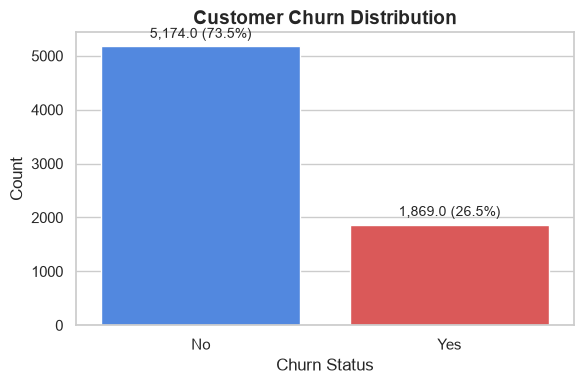

In [8]:
# Class distribution
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

print(f"Churn Counts:\n{churn_counts}\n")
print(f"Churn Percentages:\n{churn_pct.round(2)}")

# Create numerical target variable
df['Churn_Numeric'] = df['Churn'].map({'Yes': 1, 'No': 0}).astype(int)

# Quick visual of target distribution
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Churn', hue='Churn', palette=['#3b82f6', '#ef4444'], legend=False, ax=ax)
ax.set_title("Customer Churn Distribution", fontsize=14, fontweight='bold')
ax.set_xlabel("Churn Status")
ax.set_ylabel("Count")
for p in ax.patches:
    ax.annotate(f'{p.get_height():,} ({p.get_height()/len(df)*100:.1f}%)', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')
plt.tight_layout()
plt.show()


## 6. Feature Engineering
We create three high-value business features:
1. **`TotalAddonServices`**: Number of optional service add-ons active (0 to 6).
2. **`TenureGroup`**: Cohort bins (`0-12m`, `13-24m`, `25-48m`, `49-60m`, `60m+`).
3. **`HasFamily`**: Binary flag indicating whether the customer has a partner or dependents.


In [9]:
# 1. Number of add-on services
df['TotalAddonServices'] = df[addon_cols].apply(lambda row: sum(val == 'Yes' for val in row), axis=1)

# 2. Tenure cohorts
tenure_bins = [-1, 12, 24, 48, 60, 100]
tenure_labels = ['0-12m', '13-24m', '25-48m', '49-60m', '60m+']
df['TenureGroup'] = pd.cut(df['tenure'], bins=tenure_bins, labels=tenure_labels)

# 3. Family account flag
df['HasFamily'] = ((df['Partner'] == 'Yes') | (df['Dependents'] == 'Yes')).astype(int)

# Preview engineered features
df[['tenure', 'TenureGroup', 'TotalAddonServices', 'HasFamily', 'MonthlyCharges', 'TotalCharges', 'Churn']].head(8)


,tenure,TenureGroup,TotalAddonServices,HasFamily,MonthlyCharges,TotalCharges,Churn
0,1,0-12m,1,1,29.85,29.85,No
1,34,25-48m,2,0,56.95,1889.50,No
2,2,0-12m,2,0,53.85,108.15,Yes
3,45,25-48m,3,0,42.30,1840.75,No
4,2,0-12m,0,0,70.70,151.65,Yes
5,8,0-12m,3,0,99.65,820.50,Yes
6,22,13-24m,2,1,89.10,1949.40,No
7,10,0-12m,1,0,29.75,301.90,No


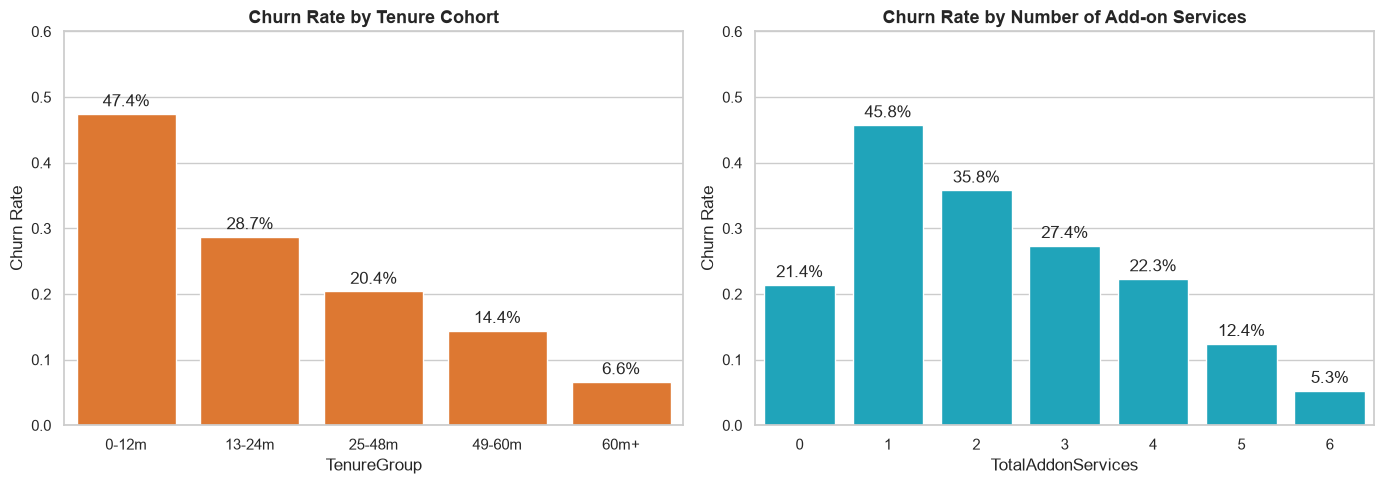

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Churn Rate by Tenure Group
tenure_churn = df.groupby('TenureGroup', observed=False)['Churn_Numeric'].mean().reset_index()
sns.barplot(data=tenure_churn, x='TenureGroup', y='Churn_Numeric', color='#f97316', ax=ax1)
ax1.set_title("Churn Rate by Tenure Cohort", fontsize=13, fontweight='bold')
ax1.set_ylabel("Churn Rate")
ax1.set_ylim(0, 0.6)
for p in ax1.patches:
    ax1.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width()/2., p.get_height()),
                 ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

# Churn Rate by Total Add-on Services
addon_churn = df.groupby('TotalAddonServices')['Churn_Numeric'].mean().reset_index()
sns.barplot(data=addon_churn, x='TotalAddonServices', y='Churn_Numeric', color='#06b6d4', ax=ax2)
ax2.set_title("Churn Rate by Number of Add-on Services", fontsize=13, fontweight='bold')
ax2.set_ylabel("Churn Rate")
ax2.set_ylim(0, 0.6)
for p in ax2.patches:
    ax2.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width()/2., p.get_height()),
                 ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


## 7. Export Cleaned Dataset

In [11]:
output_path = os.path.join("..", "data", "telco_churn_cleaned.csv")
if not os.path.exists(os.path.dirname(output_path)):
    output_path = os.path.join("data", "telco_churn_cleaned.csv")

df.to_csv(output_path, index=False)
print(f"Cleaned dataset successfully exported to: {os.path.abspath(output_path)}")
print(f"Final shape: {df.shape[0]:,} rows × {df.shape[1]} columns")


Cleaned dataset successfully exported to: C:\Users\ASUS\churn-project\data\telco_churn_cleaned.csv
Final shape: 7,043 rows × 25 columns
